# Day 3-03｜ユニフォームの色でチームを分けられるか：チームのクラスタリング

[Colab で開く](https://colab.research.google.com/github/henry753951/basketball-hackathon-course/blob/main/day3/d3_03_team_clustering_ja.ipynb)

[English](d3_03_team_clustering_en.ipynb) | [Japanese](d3_03_team_clustering_ja.ipynb) | [Traditional Chinese](d3_03_team_clustering.ipynb)


> 追跡で分かるのは同じ一時 ID かどうかであり、どのチームに属するかではない。  
> 研究用のチーム分類を初学者向けに整理し、**上半身の切り出し -> HSV 色ヒストグラム -> K-means による 2 群分け -> 元画像への表示**を行う。

## 学習目標

- 選手の矩形からユニフォームを含みやすい上半身を切り出す。
- 各画像を 2 次元の HSV ヒストグラムにし、比較できる特徴ベクトルを作る。
- 2 群の K-means を実装し、クラスタリングと既知のチーム名による分類を区別する。
- 元の矩形、切り出し画像、特徴の散布図、Team A／B の結果を照合する。

## 用語

- **切り出し画像（Crop）**：元画像から取り出した部分画像。
- **特徴ベクトル（Feature / embedding）**：画像を距離計算できる数値列にしたもの。
- **HSV**：色相、彩度、明度。ユニフォームの色を表現しやすい色空間。
- **クラスタリング（Clustering）**：正しいチーム名を与えず、類似性からデータを分けること。
- **K-means**：最も近い中心への割り当てと、中心の更新を繰り返す方法。


## 参照した研究コードとの関係

参照プロジェクトも選手の画像を集め、色ヒストグラムまたは画像埋め込みを取り、`KMeans(n_clusters=2)` で 2 チームに分ける。本演習はその流れを保ち、次の三点を簡略化する。

1. 代表する 1 フレームを使い、四つの図を直接比較できるようにする。
2. 大きな埋め込みモデルを導入する前に、HSV ヒストグラムを使う。
3. NumPy で 2 群の K-means を書き、各処理を確認できるようにする。

実際のプロジェクトでは複数フレームから画像を集め、同じ `track_id` 内で投票すると安定しやすい。


## 演習の流れ

1. 十分な人数が写り、両チームのユニフォームが見えるフレームを選ぶ。
2. 選手を検出し、各矩形から上半身を切り出す。
3. 矩形と切り出し画像の番号を照合し、床や観客を切り出していないか確認する。
4. 切り出し画像を HSV ヒストグラムに変換する。
5. K-means で 2 群に分け、PCA は 2 次元の表示だけに使う。
6. 元画像に Team A／B の色を付け、失敗例を考える。


In [1]:
import os
os.environ["BASKETBALL_COURSE_LANGUAGE"] = "ja"

# 教材環境を準備し、完了を短く表示します。
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path
import subprocess
import sys

from IPython.display import Markdown, display

DRIVE_MOUNTED = False
if "google.colab" in sys.modules:
    from google.colab import drive

    try:
        drive.mount("/content/drive")
        DRIVE_MOUNTED = True
    except NotImplementedError:
        print("この Colab ランタイムでは Drive をマウントできないため、ローカルの /content を使います。")

COURSE_ROOT_HINT = (
    Path("/content/drive/MyDrive/basketball_hackathon/course")
    if DRIVE_MOUNTED
    else next(
        (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
         if (p / "src" / "course_setup.py").exists()),
        Path("/content/basketball_hackathon/course"),
    )
)
if not (COURSE_ROOT_HINT / "src" / "course_setup.py").exists() and "google.colab" in sys.modules:
    COURSE_ROOT_HINT.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run([
        "git", "clone", "--depth", "1", "https://github.com/henry753951/basketball-hackathon-course.git", str(COURSE_ROOT_HINT)
    ], check=True)
if str(COURSE_ROOT_HINT) not in sys.path:
    sys.path.insert(0, str(COURSE_ROOT_HINT))

from src.course_setup import bootstrap_course_repo  # noqa: E402

with redirect_stdout(StringIO()):
    COURSE_ROOT = bootstrap_course_repo(COURSE_ROOT_HINT, mount_drive=False)
display(Markdown(
    f"✅ **教材環境の準備ができました**  \n"
    f"プロジェクトルート：`{COURSE_ROOT}`"
))


✅ **教材環境の準備ができました**  
プロジェクトルート：`/Users/henry753951/Developer/sandbox/basketball-hackathon-course`

## Step 1｜代表フレームを選び、選手の矩形を求める

両チームのユニフォームが見える画像を使う。検出された選手が 2 人未満なら `FRAME_INDEX` を変える。切り出し画像が小さすぎる場合は `IMGSZ` を大きくする。


In [2]:
# フレーム、モデル、出力パスを設定し、選手を検出します。
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np

from src.cv_utils import save_json
from src.yolo_utils import (
    PLAYER_CLASS_NAMES,
    detector_model_path,
    first_reference_video,
    read_video_frame,
    run_detector_on_image,
)

VIDEO_PATH = first_reference_video(COURSE_ROOT)
MODEL_PATH = detector_model_path(COURSE_ROOT)
FRAME_INDEX = 30
CONF = 0.25
IMGSZ = 960
OUTPUT_IMAGE = COURSE_ROOT / "assets" / "results" / "d3_03_team_clustering.png"
OUTPUT_JSON = OUTPUT_IMAGE.with_suffix(".json")

frame = read_video_frame(VIDEO_PATH, FRAME_INDEX)
detections, _ = run_detector_on_image(
    MODEL_PATH, frame, conf=CONF, imgsz=IMGSZ, frame_index=FRAME_INDEX
)
players = [det for det in detections if det.class_name in PLAYER_CLASS_NAMES]
if len(players) < 2:
    raise RuntimeError("検出された選手が 2 人未満です。FRAME_INDEX を変えて再実行してください。")

print("video:", VIDEO_PATH)
print("frame:", FRAME_INDEX)
print("player boxes:", len(players))


video: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/raw/reference_videos/boston-celtics-new-york-knicks-game-1-q1-01.54-01.48.mp4
frame: 30
player boxes: 10


## Step 2｜ユニフォームを含みやすい領域だけ切り出す

矩形全体には床、靴、背景も入る。横幅の中央約 60%、高さの上から約 10%～65% を残して胴体を近似する。これは人体姿勢モデルではなく、分かりやすい経験的な規則である。


In [3]:
# 各矩形から上半身を切り出し、元の矩形番号を保持します。
def torso_crop(image, bbox_xyxy):
    '''[x1, y1, x2, y2] 矩形の中央上半身を切り出します。'''
    image_h, image_w = image.shape[:2]
    x1, y1, x2, y2 = map(float, bbox_xyxy)
    box_w, box_h = x2 - x1, y2 - y1

    # 左右の背景と頭・脚を除き、ユニフォームの領域に絞ります。
    crop_x1 = int(np.clip(x1 + 0.20 * box_w, 0, image_w - 1))
    crop_x2 = int(np.clip(x2 - 0.20 * box_w, crop_x1 + 1, image_w))
    crop_y1 = int(np.clip(y1 + 0.10 * box_h, 0, image_h - 1))
    crop_y2 = int(np.clip(y1 + 0.65 * box_h, crop_y1 + 1, image_h))
    return image[crop_y1:crop_y2, crop_x1:crop_x2]

crops, valid_players, source_indices = [], [], []
for source_index, player in enumerate(players):
    crop = torso_crop(frame, player.bbox_xyxy)
    if crop.shape[0] < 8 or crop.shape[1] < 8:
        continue  # 小さすぎる画像は色情報が不足するため除きます。
    crops.append(crop)
    valid_players.append(player)
    source_indices.append(source_index)

if len(crops) < 2:
    raise RuntimeError("有効なユニフォーム画像が 2 枚未満です。選手が明瞭なフレームを選んでください。")


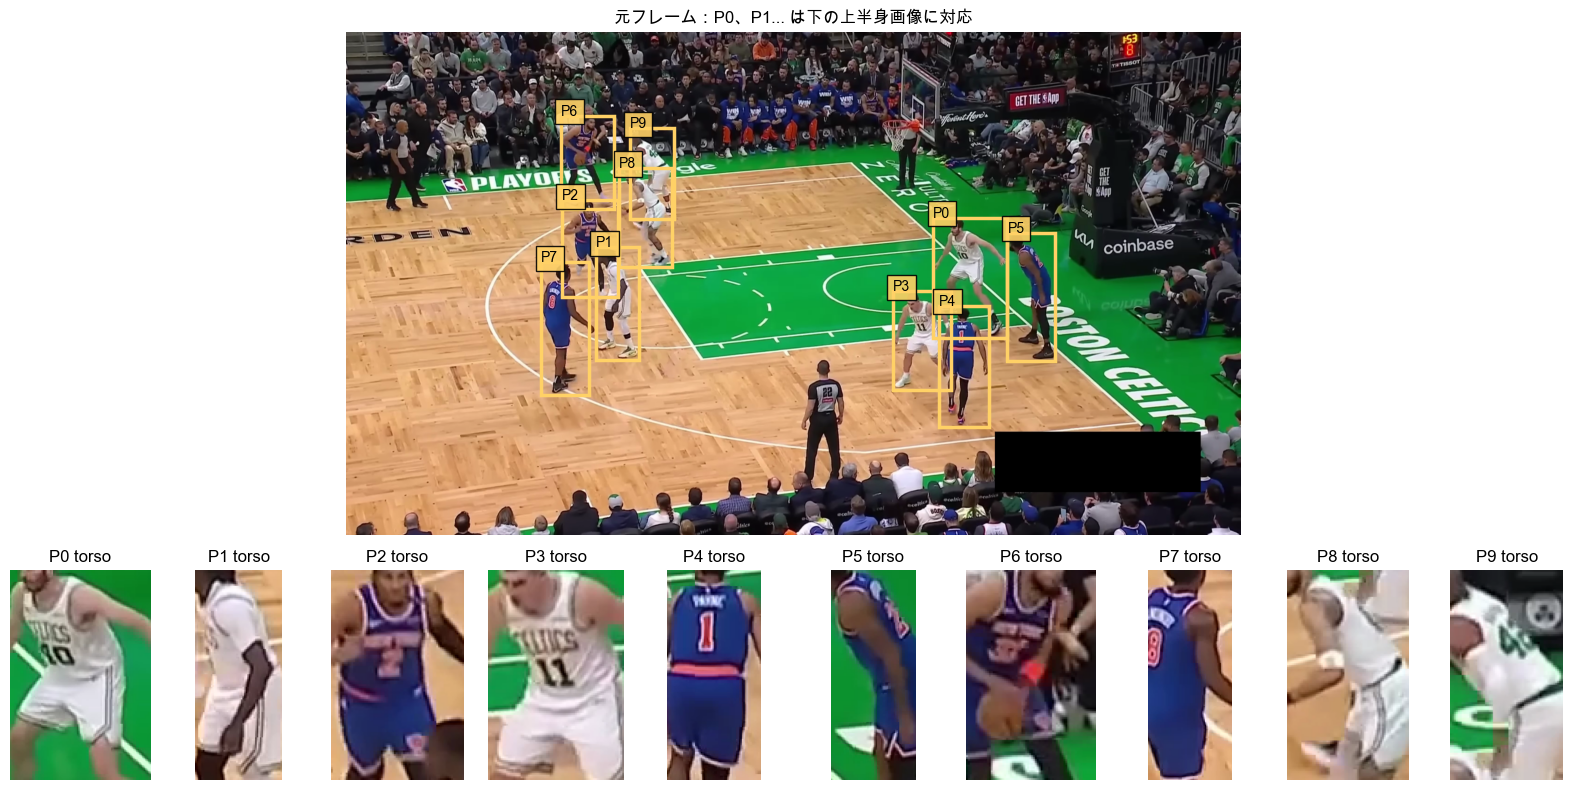

In [4]:
# 元画像の矩形番号と上半身画像の番号を並べて確認します。
fig = plt.figure(figsize=(16, 8))
grid = fig.add_gridspec(2, max(3, len(crops)), height_ratios=[2.4, 1])
ax_main = fig.add_subplot(grid[0, :])
ax_main.imshow(frame)
ax_main.set_title("元フレーム：P0、P1... は下の上半身画像に対応")
ax_main.axis("off")
for local_index, player in enumerate(valid_players):
    x1, y1, x2, y2 = player.bbox_xyxy
    ax_main.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                                fill=False, edgecolor="#FFD166", linewidth=2.5))
    ax_main.text(x1, y1, f"P{local_index}", color="black", weight="bold",
                 bbox={"facecolor": "#FFD166", "alpha": 0.9})

for index, crop in enumerate(crops):
    ax = fig.add_subplot(grid[1, index])
    ax.imshow(crop)
    ax.set_title(f"P{index} torso")
    ax.axis("off")
plt.tight_layout()
plt.show()


## Step 3｜異なる大きさの画像を固定長の色特徴にする

HSV 空間で色相 H と彩度 S の組み合わせを数え、2 次元のヒストグラムを作る。これをベクトルにし、$L_2$ 正規化する。

$$
\hat{\mathbf{h}}=\frac{\mathbf{h}}{\lVert\mathbf{h}\rVert_2+\epsilon}.
$$

元画像の大きさにかかわらず、同じ長さの特徴になる。正規化により、切り出しサイズによる総画素数の影響を抑える。


In [5]:
# 各 RGB 画像を正規化した HSV(H,S) ヒストグラムにします。
def color_hist_embedding(crop_rgb, hue_bins=12, saturation_bins=8):
    '''正規化した 2 次元 H／S ヒストグラムを、1 本の特徴ベクトルとして返します。'''
    hsv = cv2.cvtColor(np.ascontiguousarray(crop_rgb), cv2.COLOR_RGB2HSV)
    histogram = cv2.calcHist(
        [hsv], [0, 1], None,
        [hue_bins, saturation_bins],
        [0, 180, 0, 256],
    ).flatten().astype(np.float32)
    norm = float(np.linalg.norm(histogram))
    return histogram / max(norm, 1e-12)

features = np.vstack([color_hist_embedding(crop) for crop in crops])
print("number of crops:", len(crops))
print("feature matrix shape:", features.shape)
print("各行は選手の画像、各列は H／S の色区間です。")


number of crops: 10
feature matrix shape: (10, 96)
各行は選手の画像、各列は H／S の色区間です。


## Step 4｜2 群の K-means で割り当てと更新を繰り返す

画像 $i$ の特徴 $\mathbf{x}_i$ を、最も近い中心に割り当てる。

$$
c_i=\arg\min_{k\in\{0,1\}}\lVert\mathbf{x}_i-\boldsymbol{\mu}_k\rVert_2^2.
$$

同じ群の特徴の平均で $\boldsymbol{\mu}_k$ を更新する。割り当てが変わらなくなるか、反復上限まで繰り返す。`0/1` に実際のチーム名の意味はないため、Team A／B と呼ぶ。


In [6]:
# NumPy で 2 群の K-means を実装し、各処理を確認します。
def kmeans_two_clusters(feature_matrix, max_iterations=50):
    if len(feature_matrix) < 2:
        raise ValueError("K-means には少なくとも 2 件のデータが必要です。")

    # 初期中心を離すため、P0 と P0 から最も遠い点を選びます。
    first_center_index = 0
    distances_from_first = np.linalg.norm(
        feature_matrix - feature_matrix[first_center_index], axis=1
    )
    second_center_index = int(np.argmax(distances_from_first))
    centers = feature_matrix[[first_center_index, second_center_index]].copy()
    labels = np.full(len(feature_matrix), -1, dtype=int)

    iterations_run = 0
    for iteration in range(max_iterations):
        iterations_run = iteration + 1
        # distances[i, k]：選手 i と群中心 k の距離。
        distances = np.linalg.norm(
            feature_matrix[:, None, :] - centers[None, :, :], axis=2
        )
        new_labels = distances.argmin(axis=1)
        if np.array_equal(new_labels, labels):
            break
        labels = new_labels

        # 各中心を群の平均に更新します。空の群では元の中心を保持します。
        for cluster_id in (0, 1):
            members = feature_matrix[labels == cluster_id]
            if len(members) > 0:
                centers[cluster_id] = members.mean(axis=0)
    return labels, centers, iterations_run

team_labels, cluster_centers, iterations = kmeans_two_clusters(features)
print("iterations:", iterations)
print("Team A members:", np.where(team_labels == 0)[0].tolist())
print("Team B members:", np.where(team_labels == 1)[0].tolist())


iterations: 3
Team A members: [0, 1, 3, 5, 8, 9]
Team B members: [2, 4, 6, 7]


## Step 5｜特徴を 2 次元に圧縮して表示する

HSV ヒストグラムは高次元なので、そのまま平面に描けない。PCA の基本となる中心化と SVD で二つの方向に投影する。**K-means は元の全特徴を使い、2 次元座標は表示にしか使わない。**


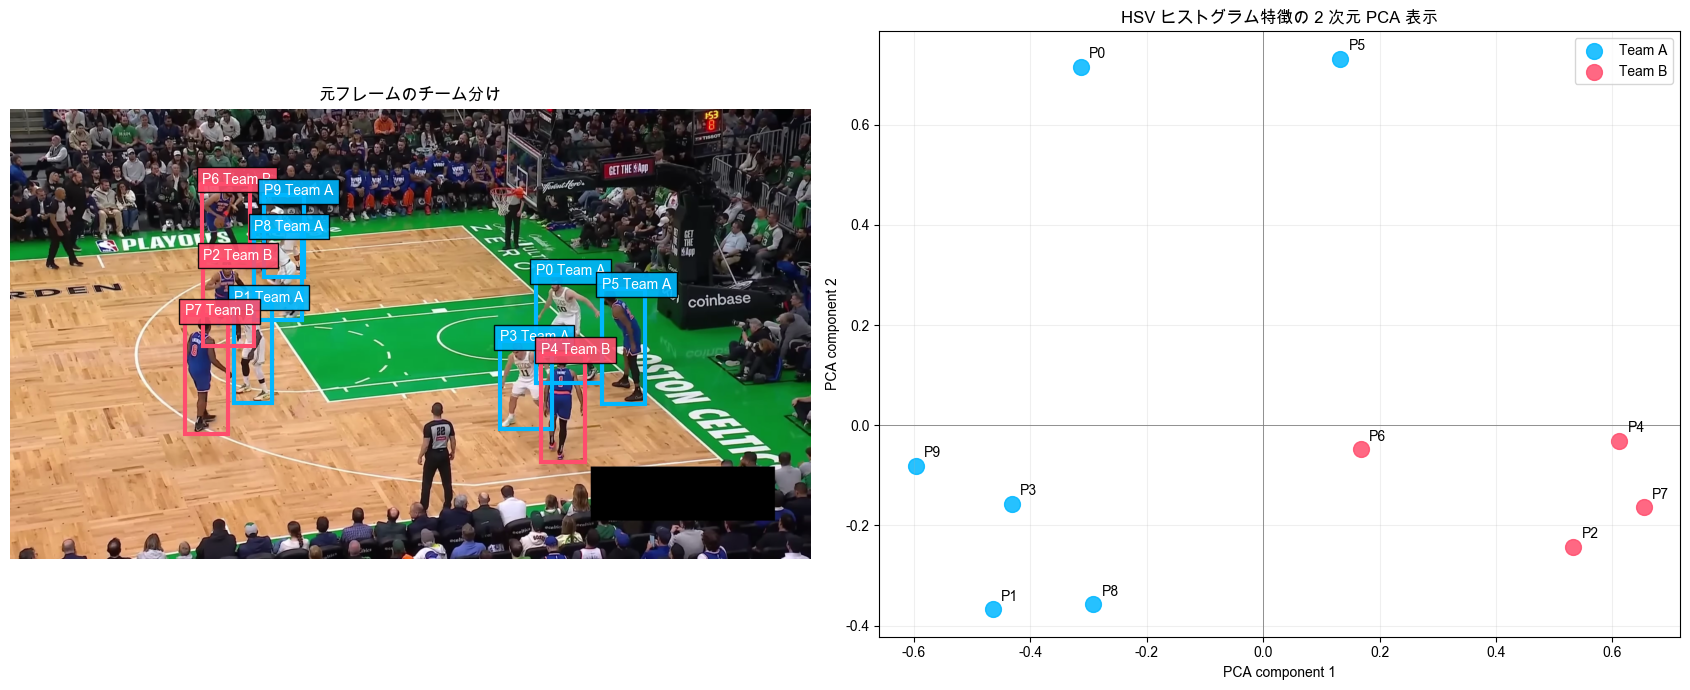

saved image: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d3_03_team_clustering.png
saved data: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d3_03_team_clustering.json


In [7]:
# 切り出し画像、2 次元特徴、元画像のチーム表示を並べます。
centered_features = features - features.mean(axis=0, keepdims=True)
_, _, vh = np.linalg.svd(centered_features, full_matrices=False)
component_count = min(2, vh.shape[0])
feature_2d = centered_features @ vh[:component_count].T
if component_count == 1:
    feature_2d = np.column_stack([feature_2d[:, 0], np.zeros(len(feature_2d))])

team_colors = {0: "#00B7FF", 1: "#FF4D6D"}
team_names = {0: "Team A", 1: "Team B"}
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# 左：元の矩形に群を表示し、チームラベルとの対応を確認します。
axes[0].imshow(frame)
axes[0].set_title("元フレームのチーム分け")
axes[0].axis("off")
result_rows = []
for index, (player, cluster_id) in enumerate(zip(valid_players, team_labels)):
    x1, y1, x2, y2 = player.bbox_xyxy
    color = team_colors[int(cluster_id)]
    axes[0].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                                fill=False, edgecolor=color, linewidth=3))
    axes[0].text(x1, y1, f"P{index} {team_names[int(cluster_id)]}",
                 color="white", weight="bold",
                 bbox={"facecolor": color, "alpha": 0.9})
    result_rows.append({
        "frame": FRAME_INDEX,
        "player_index": index,
        "source_detection_index": source_indices[index],
        "team_cluster": int(cluster_id),
        "team_name": team_names[int(cluster_id)],
        "bbox_xyxy": [float(value) for value in player.bbox_xyxy],
    })

# 右：各点は上半身画像です。近い点ほど HSV 分布が似ています。
for cluster_id in (0, 1):
    mask = team_labels == cluster_id
    axes[1].scatter(feature_2d[mask, 0], feature_2d[mask, 1], s=130,
                    color=team_colors[cluster_id], label=team_names[cluster_id], alpha=0.85)
for index, (x, y) in enumerate(feature_2d):
    axes[1].annotate(f"P{index}", (x, y), xytext=(6, 6), textcoords="offset points")
axes[1].axhline(0, color="gray", linewidth=0.6)
axes[1].axvline(0, color="gray", linewidth=0.6)
axes[1].set_title("HSV ヒストグラム特徴の 2 次元 PCA 表示")
axes[1].set_xlabel("PCA component 1")
axes[1].set_ylabel("PCA component 2")
axes[1].legend()
axes[1].grid(alpha=0.2)

OUTPUT_IMAGE.parent.mkdir(parents=True, exist_ok=True)
plt.tight_layout()
fig.savefig(OUTPUT_IMAGE, dpi=160, bbox_inches="tight")
plt.show()
save_json(result_rows, OUTPUT_JSON)
print("saved image:", OUTPUT_IMAGE)
print("saved data:", OUTPUT_JSON)


## 結果の読み方と制約

二色に分かれたかだけでなく、次の順に確認する。

1. **矩形は正しいか。** 審判や観客を囲んだ矩形は、その後のクラスタリングでは直せない。
2. **切り出し画像にユニフォームがあるか。** 床、肌、影が多いと色特徴に混ざる。
3. **同じチームの点が 2 次元図で近いか。** 重なる原因には照明、似た色のユニフォーム、PCA による圧縮がある。
4. **元画像の Team A／B は妥当か。** 群番号は実際のチーム名ではなく、背番号の認識も行わない。

### 実際のプロジェクトへの拡張

- 複数フレームから画像を集め、同じ `track_id` の多数決でチームを決める。
- 審判を除外するか、審判用の第 3 群を導入する。
- 色ヒストグラムを学習済みの画像埋め込みに置き換える。
- チーム情報と背番号モデル／OCR を組み合わせ、選手を識別する。

## 出力

- `assets/results/d3_03_team_clustering.png`：元画像のチーム分けと特徴の散布図。
- `assets/results/d3_03_team_clustering.json`：各選手の矩形の Team A／B。
